**Task 3: Encoding Categorical Variables**

In [1]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

In [2]:
# Load dataset
df_clean = pd.read_csv('C:/Users/User/Desktop/PG230/PG230_Bank_Loan_default_prediction/results/outputs/missing_values.csv')

In [3]:
# Identify categorical columns
cat_cols = df_clean.select_dtypes(include='object').columns
print("Categorical Columns:", cat_cols.tolist())

Categorical Columns: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']


* Label encoding is applied to peron_gender and previous_loan_defaults_on_file due to them being binary categories which means they only have two outputs.

In [4]:
# Label Encode binary categories
le = LabelEncoder()
df_clean['person_gender'] = le.fit_transform(df_clean['person_gender'])  # male/female
df_clean['previous_loan_defaults_on_file'] = le.fit_transform(df_clean['previous_loan_defaults_on_file'])  # yes/no

* One-hot encoding applied to person_education, person_home_ownership, loan_intent due to them having multiple outputs.

In [5]:
# One-Hot Encode multi-class categorical variables
df_clean = pd.get_dummies(df_clean,
                           columns=['person_education','person_home_ownership','loan_intent'],
                           drop_first=True)

* Shows correlations between all categorical features after encoding

In [6]:
label_cols = ['person_gender', 'previous_loan_defaults_on_file']
onehot_prefixes = ['person_education_', 'person_home_ownership_', 'loan_intent_']

encoded_cols = label_cols.copy()
for prefix in onehot_prefixes:
    encoded_cols.extend([col for col in df_clean.columns if col.startswith(prefix)])

df_encoded_bool = df_clean[encoded_cols].astype(int)

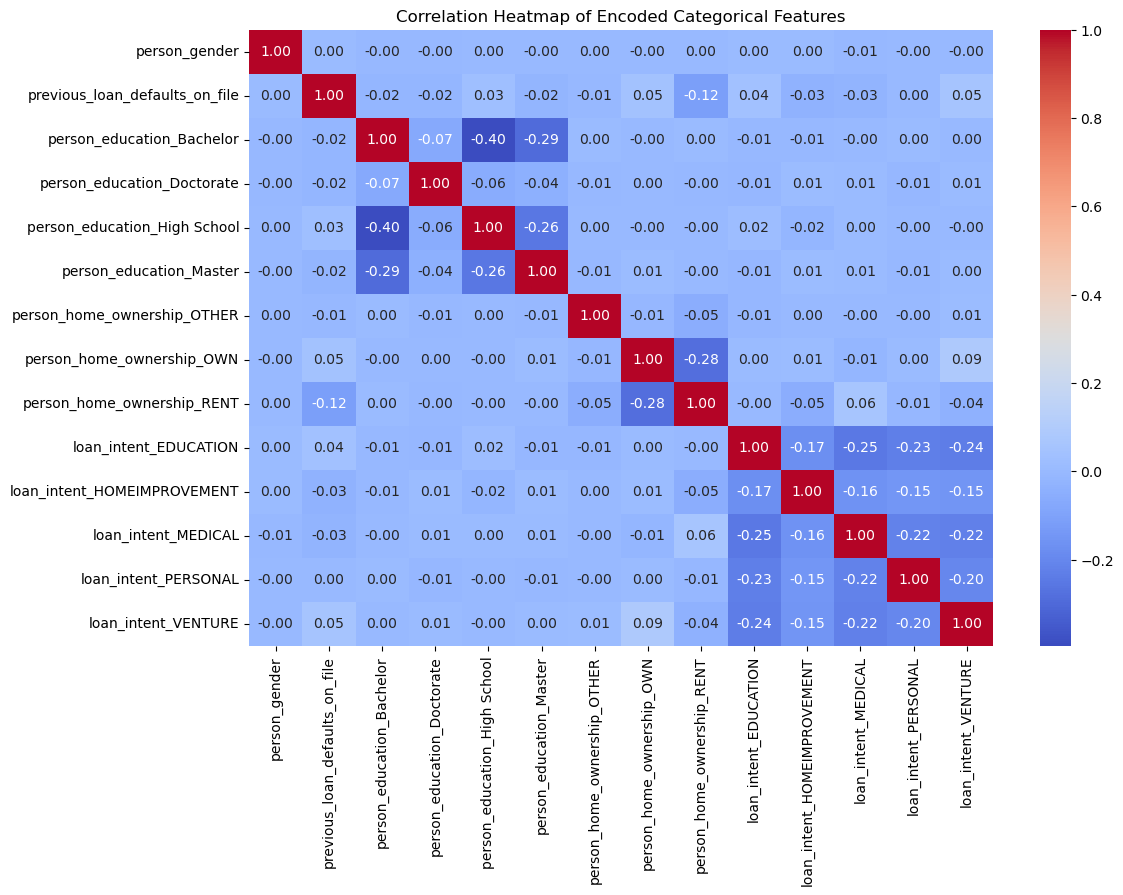

In [7]:
plt.figure(figsize=(12,8))
sns.heatmap(df_encoded_bool.corr(), cmap='coolwarm', annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Encoded Categorical Features")
plt.show()

In [8]:
# Display first five rows to check encoding
df_clean.head()

,person_age,person_gender,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,...,person_education_High School,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,21,0,12282,0,1000,11.14,0.08,2,504,1,...,True,False,False,True,False,True,False,False,False,False
1,21,0,12951,0,2500,7.14,0.19,2,532,0,...,True,False,False,True,False,False,False,False,False,True
2,21,0,12739,0,1600,14.74,0.13,3,640,0,...,True,False,False,True,False,False,False,False,False,True
3,24,0,14283,1,1750,10.99,0.12,2,679,0,...,False,True,False,False,False,True,False,False,False,False
4,24,0,13866,0,1500,7.29,0.11,3,600,1,...,False,False,False,True,False,False,False,False,True,False


In [9]:
# Create a new DataFrame with encoded categorical features
df_clean.to_csv('C:/Users/User/Desktop/PG230/PG230_Bank_Loan_default_prediction/results/outputs/encoded_data.csv', index=False)